This notebooks adds the scarches latent embeddings of each query dataset, computes a dataset specific UMAP and projects hierachical assignments from the reference (control only) to the spatial cells.

Operation(s):

1. Add scArches derived latent embedding to spatial AnnData objects
2. Compute within dataset neighbors and UMAP
3. Project into single cell UMAP space
3. Hierarchical label transfer from Level 1 through Level 5 to spatial data from reference single cell

Output(s):

1. DATADIR/7_spatial/SP*-*.h5ad

Requirement(s):

1. DATADIR/6_NC_projection/all_integrated/HypoMap3D_full.h5ad
2. DATADIR/7_spatial/bounded/SP*-*.h5ad

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import logging
import os

from pathlib import Path

import anndata as ad
import pandas as pd
import numpy as np
import rapids_singlecell as rsc

from dotenv import dotenv_values
from matplotlib import pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

from hm3d_utils.neighbors import knn_graph
from hm3d_utils.utils import csr_row_normalize
from hm3d_utils.clustering import project_query
from hm3d_utils.manifold import project_to_ref_umap
from project_utils import FileTracker

warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "7_spatial"
QC_FIG_OUTDIR = DATADIR / "7_spatial" / "qc_figure_objects" # for unfiltered data intended for qc figures

# Notebook constants
WNN_K = 50
USE_GPU = True

In [4]:
os.makedirs(OUTDIR, exist_ok=True)
os.makedirs(QC_FIG_OUTDIR, exist_ok=True)

tracker = FileTracker(log_file=DATADIR/'tracked_files.toml')

### Load Reference

In [5]:
reference_path = DATADIR / '6_NC_projection' / 'all_integrated' / 'HypoMap3D_full.h5ad'
ref_adata = ad.read_h5ad(reference_path, backed="r")
ref_adata = ref_adata[ref_adata.obs.IsControl].to_memory()
ref_adata

AnnData object with n_obs × n_vars = 898050 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'L1', 'L2', 'L3', 'L4', 'L5', 'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated', 'C465_named_propagated', 'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 'cluster_id_label_propagated', 'XistExpressing', 'UtyExpressing', 'sex_per_sample_inferred', 'xist_pct_per_sample', 'uty_pct_per_sample', 'L1_descr_v0.6', 'L2_descr_v0.6', 'L3_descr_v0.6', 'L4_descr_v0.6', 'L5_descr_v0.6', 'L2_prelim', 'L3_prelim', 'L4_prelim', 'L5_prelim'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTF

In [6]:
# # In order to compute bipartite SNN we need reference neighbourhoods
# if f'{WNN_K}nn_adjacencies' not in ref_adata.obsp.keys():
#     logging.warning('Precomputed reference neighbor adjacencies not found. Computing them live.')
    
#     D = knn_graph(
#         ref_adata.obsm['X_embed'],
#         k=WNN_K+1, # +1 for self reference
#         use_gpu=USE_GPU
#     )
#     D.eliminate_zeros() # remove self reference
    
#     ref_adata.obsp[f'{WNN_K}nn_adjacencies'] = (D > 0)

### Project Spatial

In [7]:
qry_adata_paths = sorted((OUTDIR / "bounded").glob('SP*-*.h5ad'))

#special case for unbounded data required for figures
unbounded_openst_path = OUTDIR / "harmonized" / "SP2-03_no_qc.h5ad"
qry_adata_paths.append(unbounded_openst_path)

print(qry_adata_paths)


[PosixPath('/REDACTED-path/HypoMap3D-data/v0.9/7_spatial/harmonized/SP2-03_no_qc.h5ad')]


Processing SP2-01 dataset.
Loaded SP2-01 dataset.
Transferred SP2-01 scarches embedding.
Constructed SP2-01 spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs


2026-06-11 13:26:00 | [WARNING] 
            Precomputed reference neighbor adjacencies, `.obsp['50nn_adjacencies']`, not found. 
            Computing reference 50 neighbors and adding to `.obsp['50nn_adjacencies']`.
            


	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-01 into single cell reference UMAP embedding.
Computed SP2-01 path probabilities.
Saved SP2-01 to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/SP2-01.h5ad.


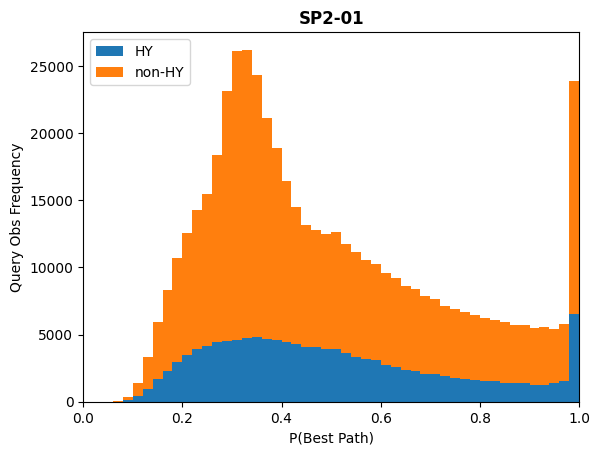

Processing SP2-01_no_qc dataset.
Loaded SP2-01_no_qc dataset.
Transferred SP2-01_no_qc scarches embedding.
Constructed SP2-01_no_qc spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-01_no_qc into single cell reference UMAP embedding.
Computed SP2-01_no_qc path probabilities.
Saved SP2-01_no_qc to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/qc_figure_objects/SP2-01_no_qc.h5ad.


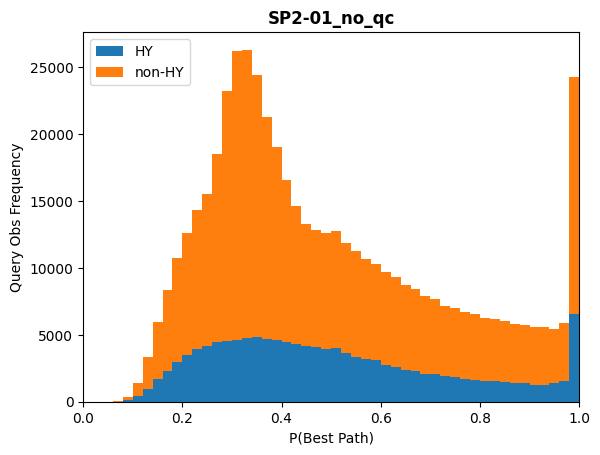

Processing SP2-02 dataset.
Loaded SP2-02 dataset.
Transferred SP2-02 scarches embedding.
Constructed SP2-02 spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-02 into single cell reference UMAP embedding.
Computed SP2-02 path probabilities.
Saved SP2-02 to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/SP2-02.h5ad.


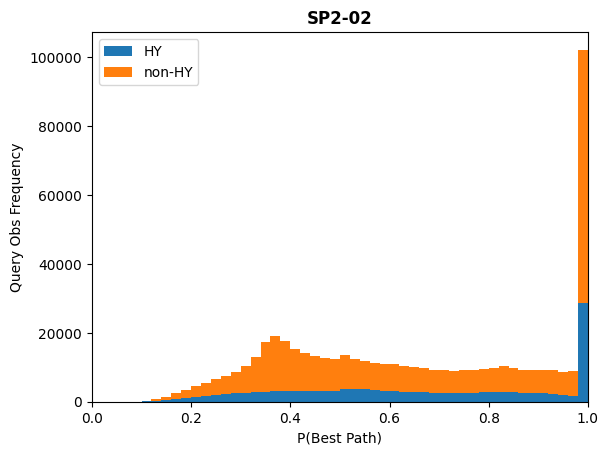

Processing SP2-02_no_qc dataset.
Loaded SP2-02_no_qc dataset.
Transferred SP2-02_no_qc scarches embedding.
Constructed SP2-02_no_qc spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-02_no_qc into single cell reference UMAP embedding.
Computed SP2-02_no_qc path probabilities.
Saved SP2-02_no_qc to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/qc_figure_objects/SP2-02_no_qc.h5ad.


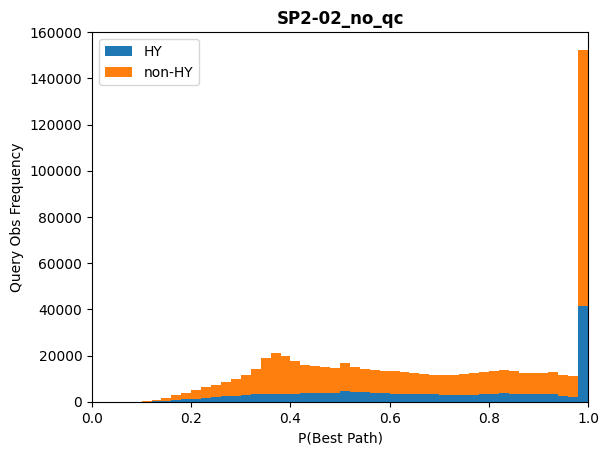

Processing SP2-03 dataset.
Loaded SP2-03 dataset.
Transferred SP2-03 scarches embedding.
Constructed SP2-03 spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-03 into single cell reference UMAP embedding.
Computed SP2-03 path probabilities.
Saved SP2-03 to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/SP2-03.h5ad.


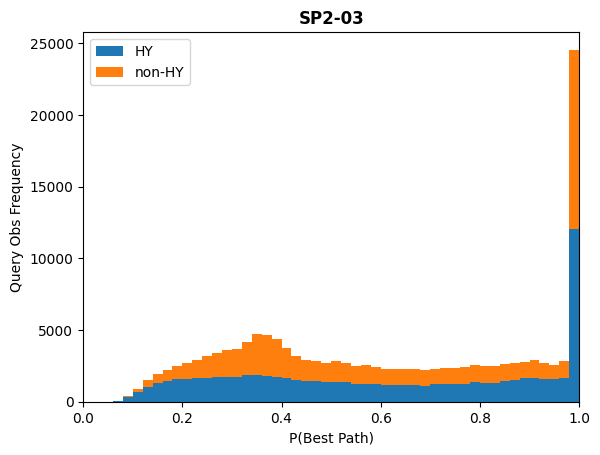

Processing SP2-03_no_qc dataset.
Loaded SP2-03_no_qc dataset.
Transferred SP2-03_no_qc scarches embedding.
Constructed SP2-03_no_qc spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-03_no_qc into single cell reference UMAP embedding.
Computed SP2-03_no_qc path probabilities.
Saved SP2-03_no_qc to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/qc_figure_objects/SP2-03_no_qc.h5ad.


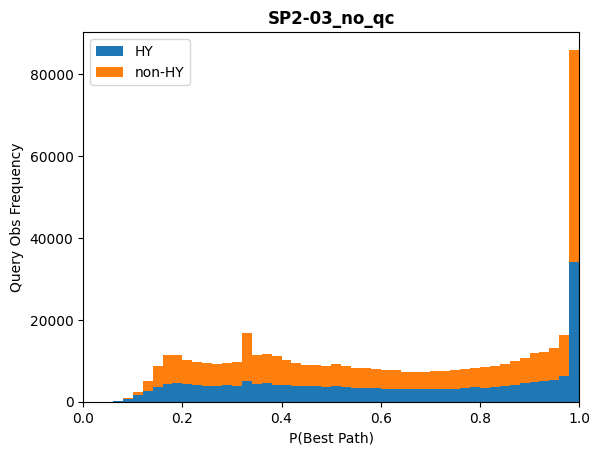

Processing SP2-04 dataset.
Loaded SP2-04 dataset.
Transferred SP2-04 scarches embedding.
Constructed SP2-04 spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-04 into single cell reference UMAP embedding.
Computed SP2-04 path probabilities.
Saved SP2-04 to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/SP2-04.h5ad.


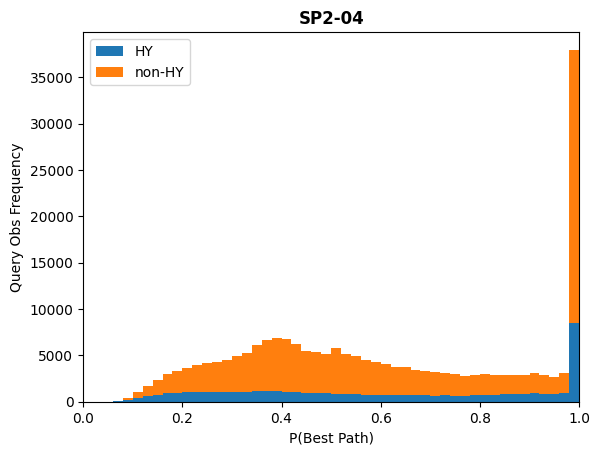

Processing SP2-04_no_qc dataset.
Loaded SP2-04_no_qc dataset.
Transferred SP2-04_no_qc scarches embedding.
Constructed SP2-04_no_qc spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-04_no_qc into single cell reference UMAP embedding.
Computed SP2-04_no_qc path probabilities.
Saved SP2-04_no_qc to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/qc_figure_objects/SP2-04_no_qc.h5ad.


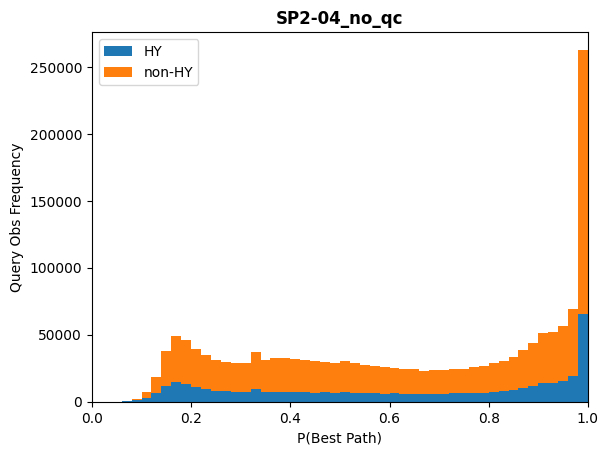

Processing SP2-03_no_qc_unbounded dataset.
Loaded SP2-03_no_qc_unbounded dataset.
Transferred SP2-03_no_qc_unbounded scarches embedding.
Constructed SP2-03_no_qc_unbounded spatial-only UMAP embedding.


  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
Projected SP2-03_no_qc_unbounded into single cell reference UMAP embedding.
Computed SP2-03_no_qc_unbounded path probabilities.
Saved SP2-03_no_qc_unbounded to disk  --> /REDACTED-path/HypoMap3D-data/v0.9/7_spatial/qc_figure_objects/SP2-03_no_qc_unbounded.h5ad.


In [8]:
for adata_path in qry_adata_paths:
    
    stem = adata_path.stem
    if adata_path == unbounded_openst_path: #special case for unbounded data required for figures
        stem += "_unbounded"

    print(f"Processing {stem} dataset.")
    embedding_path = OUTDIR / "embeddings" / f"{stem}_X_embed.csv.gz"
    
    if not embedding_path.exists():
        print(f'Skipping {stem} as projected embedding was not found at {embedding_path}')
        
    # --------------------------------- Load Data -------------------------------- #

    qry_adata = ad.read_h5ad(adata_path)
    
    print(f"Loaded {stem} dataset.")
    
    # --------------------------- Add X_embed to .obsm --------------------------- #
    
    X_embed_df = pd.read_csv(embedding_path, index_col=0)
    
    assert np.all(qry_adata.obs.index.isin(X_embed_df.index)), 'Obs are missing the projected embeddings.'
    
    qry_adata.obsm['X_embed'] = X_embed_df.loc[qry_adata.obs_names].values
    
    print(f"Transferred {stem} scarches embedding.")
    
    # --------------------------- Construct latent UMAP of spatial-only -------------------------- #
    
    rsc.pp.neighbors(qry_adata, n_neighbors=15, use_rep='X_embed')
    rsc.tl.umap(qry_adata)
    
    print(f"Constructed {stem} spatial-only UMAP embedding.")

    # --------------------------- Project query into reference UMAP -------------------------- #
    
    qry_adata.obsm['X_umap_sc'], _ = project_to_ref_umap(
        ref_adata.obsm['X_embed'],
        qry_adata.obsm['X_embed'],
        ref_adata.obsm['X_umap'],
        spread=1.0,
        min_dist=0.5,
        verbose=True,
        use_gpu=True,
        n_epochs=100,
        seed=0
    )
    
    print(f"Projected {stem} into single cell reference UMAP embedding.")
    
    # ------------------ Get soft path probabilites per qry obs ------------------ #
        
    pathmat, P_path = project_query(
        ref_adata,
        qry_adata,
        path_keys=['L1', 'L2_prelim', 'L3_prelim', 'L4_prelim', 'L5_prelim'],
        k=WNN_K,
        use_rep='X_embed',
        use_gpu=USE_GPU
    )
    qry_adata.uns['pathmat'] = pathmat
    qry_adata.obsm['P_path'] = P_path
    
    print(f"Computed {stem} path probabilities.")
    
    # ------------------------- Save out processed object ----------------------- #
    
    if "no_qc" in stem:
        outfile = QC_FIG_OUTDIR / f"{stem}.h5ad"
    else:
        outfile = OUTDIR / f"{stem}.h5ad"
    with tracker.register(outfile) as tf:
        tf.set_description(f'Projected {stem}.')
        qry_adata.write_h5ad(tf.filepath)
    
    print(f"Saved {stem} to disk  --> {outfile.as_posix()}.")
    
    try: 
        bins = np.linspace(0, 1, 51)
        best_probs = P_path.max(axis=1).data
        mask = qry_adata.obs['IsHY'].values
        plt.hist(
            [
                best_probs[mask], 
                best_probs[~mask] 
            ],
            bins=bins,
            stacked=True,
            label=["HY", "non-HY"]
        )
        plt.xlim(0, 1)
        plt.xlabel('P(Best Path)')
        plt.ylabel('Query Obs Frequency')
        plt.title(stem, fontdict=dict(weight='bold'))
        plt.legend()
        plt.show()
    except:
        continue
    

In [9]:
best_indices = qry_adata.obsm['P_path'].argmax(axis=1).A1
best_L5_labels = qry_adata.uns['pathmat'][:, -1][best_indices]
best_probs = qry_adata.obsm['P_path'].max(axis=1).toarray().flatten()

In [10]:
pd.Categorical(
    best_L5_labels[
        #qry_adata.obs['IsHY']
        #& 
        (best_probs < 0.95)
    ]
).value_counts().sort_values(ascending=False).head(22)

NN5-1 Oligo 1_1-1                161159
NN5-34 Astro 1_1-1                66518
Gl5-34 LHA Cck.Ttn                24408
NN5-32 Astro 1_1-1-1              14715
Gl5-32 LHA Cck.Cxcl14             13114
NN5-6 OPC_1-1                     13069
Gb5-848 SCH Prokr2.Prr5l          11961
Gb5-854 SCH Avp.Plekhg1.Cck-1     11596
NN5-29 VLMC_2-1                   10566
NN5-39 Tanycyte_alpha2-2           9093
NN5-23 Endo_1-1                    9006
Gl5-33 LHA Cck.Hopx                8989
Gb5-844 SCH Prokr2.Tesk2           6963
NN5-9 Microglia_1-1-1              6259
NN5-25 Peri_1-1                    5094
NN5-37 Tanycyte_beta2-1            4955
Gb5-849 SCH Creb3l1.Ccn3           4786
NN5-38 Tanycyte_beta1-1            4393
Gb5-850 SCH Creb3l1.Vip            4287
NN5-40 Tanycyte_alpha2-3           3622
NN5-45 Ependymal_3-1               3254
NN5-21 Endo_2-1                    3030
Name: count, dtype: int64

In [11]:
qry_adata

AnnData object with n_obs × n_vars = 600184 × 56939
    obs: 'Dataset', 'Sample', 'Author', 'Technology', 'Donor', 'Sex', 'RegionID', 'RegionAcronym', 'RegionName'
    var: 'gene_stable_ids', 'IsHVG', 'IsCaptured'
    uns: 'neighbors', 'umap', 'pathmat'
    obsm: 'coords_ccf_mm', 'coords_source', 'X_embed', 'X_umap', 'X_umap_sc', 'P_path'
    obsp: 'distances', 'connectivities'